<center><h1>Satish_Manvika_HW6</h1></center>

Name: Manvika Satish
<br>
Github Username: manvsatish
<br>
USC ID: 5582061880

## 1. Tree-Based Methods

Import packages

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_score)
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score, RocCurveDisplay)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from xgboost import XGBClassifier

RANDOM_STATE = 552
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 180)
print("Packages imported successfully.")

Packages imported successfully.


### (a) Download the APS Failure data

In [2]:
training_path = Path("../data/aps_failure_training_set.csv")
testing_path = Path("../data/aps_failure_test_set.csv")

aps_train_raw = pd.read_csv(training_path, skiprows=20, na_values="na") #first 20 lines - license information
aps_test_raw = pd.read_csv(testing_path, skiprows=20, na_values="na")
assert aps_train_raw.shape == (60000, 171)
assert aps_test_raw.shape == (16000, 171)
assert aps_train_raw.columns.equals(aps_test_raw.columns)

print("Training-set shape:", aps_train_raw.shape)
print("Testing-set shape:", aps_test_raw.shape)
print("Number of features:", aps_train_raw.shape[1] - 1)
print("\nFirst five training rows:")
display(aps_train_raw.head())
print("\nTraining class counts:")
display(aps_train_raw["class"].value_counts().to_frame(name="Count"))
print("\nTesting class counts:")
display(aps_test_raw["class"].value_counts().to_frame(name="Count"))
print("\nMissing values:")
print("Training set:", int(aps_train_raw.isna().sum().sum()))
print("Testing set:", int(aps_test_raw.isna().sum().sum()))

Training-set shape: (60000, 171)
Testing-set shape: (16000, 171)
Number of features: 170

First five training rows:


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,ag_008,ag_009,ah_000,ai_000,aj_000,ak_000,al_000,am_0,an_000,ao_000,ap_000,aq_000,ar_000,as_000,at_000,au_000,av_000,ax_000,ay_000,ay_001,ay_002,ay_003,ay_004,ay_005,ay_006,ay_007,ay_008,ay_009,az_000,az_001,az_002,az_003,az_004,az_005,az_006,az_007,az_008,az_009,ba_000,ba_001,ba_002,ba_003,ba_004,ba_005,ba_006,ba_007,ba_008,ba_009,bb_000,bc_000,bd_000,be_000,bf_000,bg_000,bh_000,bi_000,bj_000,bk_000,bl_000,bm_000,bn_000,bo_000,bp_000,bq_000,br_000,bs_000,bt_000,bu_000,bv_000,bx_000,by_000,bz_000,ca_000,cb_000,cc_000,cd_000,ce_000,cf_000,cg_000,ch_000,ci_000,cj_000,ck_000,cl_000,cm_000,cn_000,cn_001,cn_002,cn_003,cn_004,cn_005,cn_006,cn_007,cn_008,cn_009,co_000,cp_000,cq_000,cr_000,cs_000,cs_001,cs_002,cs_003,cs_004,cs_005,cs_006,cs_007,cs_008,cs_009,ct_000,cu_000,cv_000,cx_000,cy_000,cz_000,da_000,db_000,dc_000,dd_000,de_000,df_000,dg_000,dh_000,di_000,dj_000,dk_000,dl_000,dm_000,dn_000,do_000,dp_000,dq_000,dr_000,ds_000,dt_000,du_000,dv_000,dx_000,dy_000,dz_000,ea_000,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0,1432864.0,3664156.0,1007684.0,25896.0,0.0,2551696.0,0.0,0.0,0.0,0.0,0.0,4933296.0,3655166.0,1766008.0,1132040.0,0.0,0.0,0.0,0.0,1012.0,268.0,0.0,0.0,0.0,0.0,0.0,469014.0,4239660.0,703300.0,755876.0,0.0,5374.0,2108.0,4114.0,12348.0,615248.0,5526276.0,2378.0,4.0,0.0,0.0,2328746.0,1022304.0,415432.0,287230.0,310246.0,681504.0,1118814.0,3574.0,0.0,0.0,6700214.0,0.0,10.0,108.0,50.0,2551696.0,97518.0,947550.0,799478.0,330760.0,353400.0,299160.0,305200.0,283680.0,NaN,NaN,NaN,178540.0,76698.08,6700214.0,6700214.0,6599892.0,43566.0,68656.0,54064.0,638360.0,6167850.0,1209600.0,246244.0,2.0,96.0,0.0,5245752.00,0.0,916567.68,6.0,1924.0,0.0,0.0,0.0,118196.0,1309472.0,3247182.0,1381362.0,98822.0,11208.0,1608.0,220.0,240.0,6700214.0,NaN,10476.0,1226.0,267998.0,521832.0,428776.0,4015854.0,895240.0,26330.0,118.0,0.0,532.0,734.0,4122704.0,51288.0,0.0,532572.0,0.0,18.0,5330690.0,4732.0,1126.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,62282.0,85908.0,32790.0,0.0,0.0,202710.0,37928.0,14745580.0,1876644.0,0.0,0.0,0.0,0.0,2801180.0,2445.80,2712.0,965866.0,1706908.0,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0,653294.0,1720800.0,516724.0,31642.0,0.0,1393352.0,0.0,68.0,0.0,0.0,0.0,2560898.0,2127150.0,1084598.0,338544.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,71510.0,772720.0,1996924.0,99560.0,0.0,7336.0,7808.0,13776.0,13086.0,1010074.0,1873902.0,14726.0,6.0,0.0,0.0,1378576.0,447166.0,199512.0,154298.0,137280.0,138668.0,165908.0,229652.0,87082.0,4708.0,3646660.0,86.0,454.0,364.0,350.0,1393352.0,49028.0,688314.0,392208.0,341420.0,359780.0,366560.0,NaN,NaN,NaN,NaN,NaN,6700.0,33057.51,3646660.0,3646660.0,3582034.0,17733.0,260120.0,115626.0,6900.0,2942850.0,1209600.0,0.0,NaN,NaN,NaN,2291079.36,0.0,643536.96,0.0,0.0,0.0,0.0,38.0,98644.0,1179502.0,1286736.0,336388.0,36294.0,5192.0,56.0,NaN,0.0,3646660.0,NaN,6160.0,796.0,164860.0,350066.0,272956.0,1837600.0,301242.0,9148.0,22.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3312.0,522.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33736.0,36946.0,5936.0,0.0,0.0,103330.0,16254.0,4510080.0,868538.0,0.0,0.0,0.0,0.0,3477820.0,2211.76,2334.0,664504.0,824154.0,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0,370592.0,1883374.0,292936.0,12016.0,0.0,1234132.0,0.0,0.0,0.0,0.0,0.0,2371990.0,2173634.0,300796.0,153698.0,0.0,0.0,0.0,0.0,358.0,110.0,0.0,0.0,0.0,0.0,0.0,0.0,870456.0,239798.0,1450312.0,0.0,1620.0,1156.0,1228.0,34250.0,1811606.0,710672.0,34.0,0.0,0.0,0.0,790690.0,672026.0,332340.0,254892.0,189596.0,135758.0,103552.0,81666.0,46.0,0.0,2673338.0,128.0,202.0,576.0,4.0,1234132.0,28804.0,160176.0,139730.0,137160.0,13064


Training class counts:


,Count
class,
neg,59000
pos,1000



Testing class counts:


,Count
class,
neg,15625
pos,375



Missing values:
Training set: 850015
Testing set: 228680


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Several methods can be used to handle missing data:
- **Deletion:** Remove observations or features containing missing values. This can discard substantial information when missingness is common.
- **Simple imputation:** Replace the missing values using a statistic such as mean or median of each feature.
- **K-nearest-neighbor imputation:** Estimate a missing value using observations with similar predictor values.
- **Iterative or multiple imputation:** Predict each incomplete feature using the other available features and account for uncertainty in the imputed values.
- **Model-based handling:** Use a model that can process the missing values internally.

For this analysis, I am going to use median imputation because the predictors are numeric and many of their distributions are highly skewed with large outliers. The median is less sensitive to these extreme values than the mean. To prevent information from the test set from influencing model training, the imputer is fitted using only the training data and then applied to both the training and test predictors.

#### (ii) Calculate the coefficient of variation

In [3]:
X_train_raw = aps_train_raw.drop(columns="class") #sep predictors and encode class labels. neg = 0, pos = 1
X_test_raw = aps_test_raw.drop(columns="class")
y_train = aps_train_raw["class"].map({"neg": 0, "pos": 1})
y_test = aps_test_raw["class"].map({"neg": 0, "pos": 1})
feature_names = X_train_raw.columns.tolist()
assert X_train_raw.shape == (60000, 170)
assert X_test_raw.shape == (16000, 170)
assert y_train.isna().sum() == 0
assert y_test.isna().sum() == 0

median_imputer = SimpleImputer(strategy="median") # fit median imputation using only training data
X_train = pd.DataFrame(median_imputer.fit_transform(X_train_raw), columns=feature_names, index=X_train_raw.index)
X_test = pd.DataFrame(median_imputer.transform(X_test_raw), columns=feature_names, index=X_test_raw.index)
assert X_train.shape == (60000, 170)
assert X_test.shape == (16000, 170)
assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

print("Training missing values after imputation:", int(X_train.isna().sum().sum()))
print("Testing missing values after imputation:", int(X_test.isna().sum().sum()))

feature_means = X_train.mean() # calc cv = sample standard deviation / mean for every ft
feature_sample_std = X_train.std(ddof=1)
feature_cv = feature_sample_std / feature_means

cv_table = pd.DataFrame({"Mean": feature_means, "Sample Standard Deviation": feature_sample_std, "CV": feature_cv}).sort_values("CV", ascending=False)
assert cv_table.shape == (170, 3)

print("\nCoefficient of variation calculated for",len(cv_table), "features.")
print("\nTop 20 features by CV:")
display(cv_table.head(20).round(4))

Training missing values after imputation: 0
Testing missing values after imputation: 0

Coefficient of variation calculated for 170 features.

Top 20 features by CV:


,Mean,Sample Standard Deviation,CV
cf_000,143107.5341,3.504525e+07,244.8875
co_000,143330.0177,3.504525e+07,244.5074
ad_000,143438.2921,3.504525e+07,244.3228
cs_009,770.5097,1.833278e+05,237.9306
dh_000,4392.6408,5.412441e+05,123.2161
dj_000,37.2713,4.379166e+03,117.4942
ag_000,219.1577,2.036364e+04,92.9178
as_000,125.4079,1.095219e+04,87.3325
ay_009,1149.6196,9.741156e+04,84.7337
ak_000,907.6607,7.299859e+04,80.4250


#### (iii) Plot a correlation matrix

Correlation matrix shape: (170, 170)


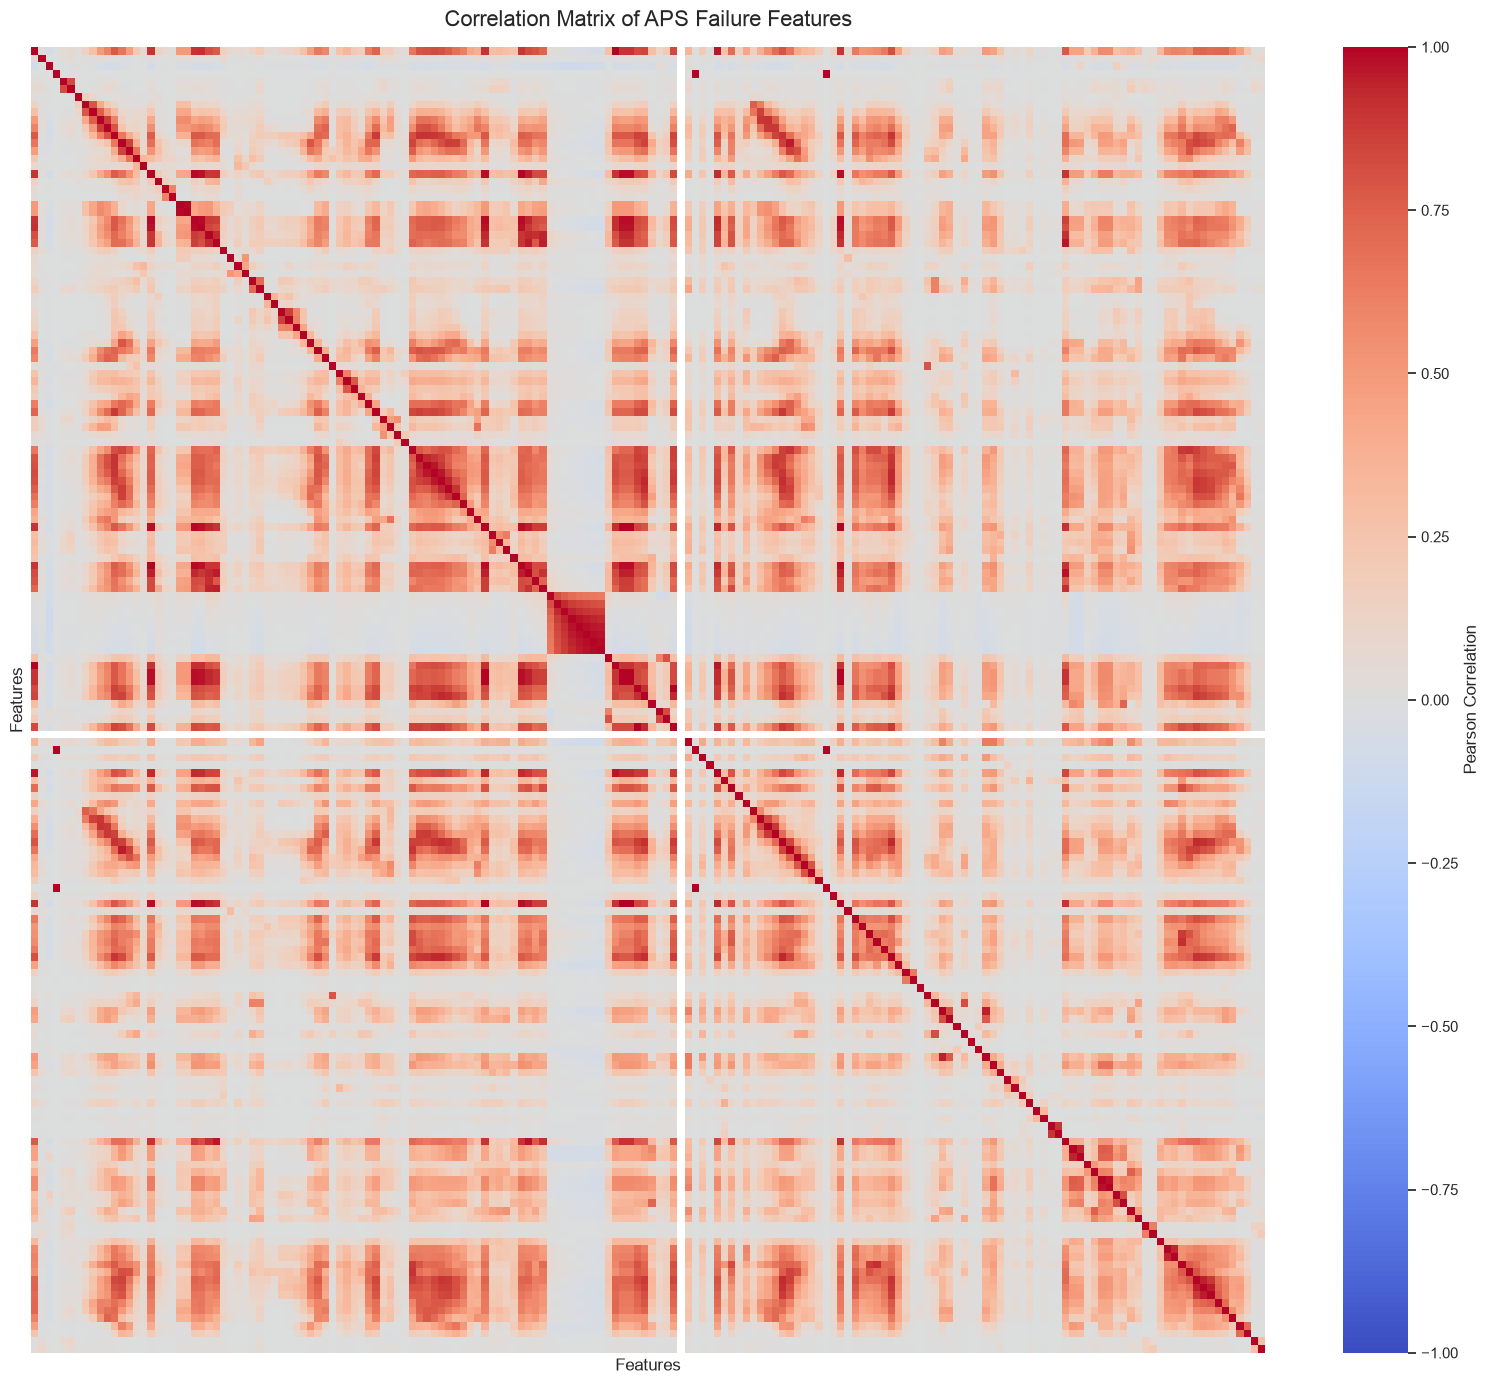

In [4]:
correlation_matrix = X_train.corr() #calc the feature correlation matrix using training set

assert correlation_matrix.shape == (170, 170)
print("Correlation matrix shape:", correlation_matrix.shape)

plt.figure(figsize=(16, 14))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=False, yticklabels=False, cbar_kws={"label": "Pearson Correlation"})
plt.title("Correlation Matrix of APS Failure Features", fontsize=16, pad=15)
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

Number of selected features: 13
Features with the highest CV:
1. cf_000
2. co_000
3. ad_000
4. cs_009
5. dh_000
6. dj_000
7. ag_000
8. as_000
9. ay_009
10. ak_000
11. az_009
12. ch_000
13. au_000


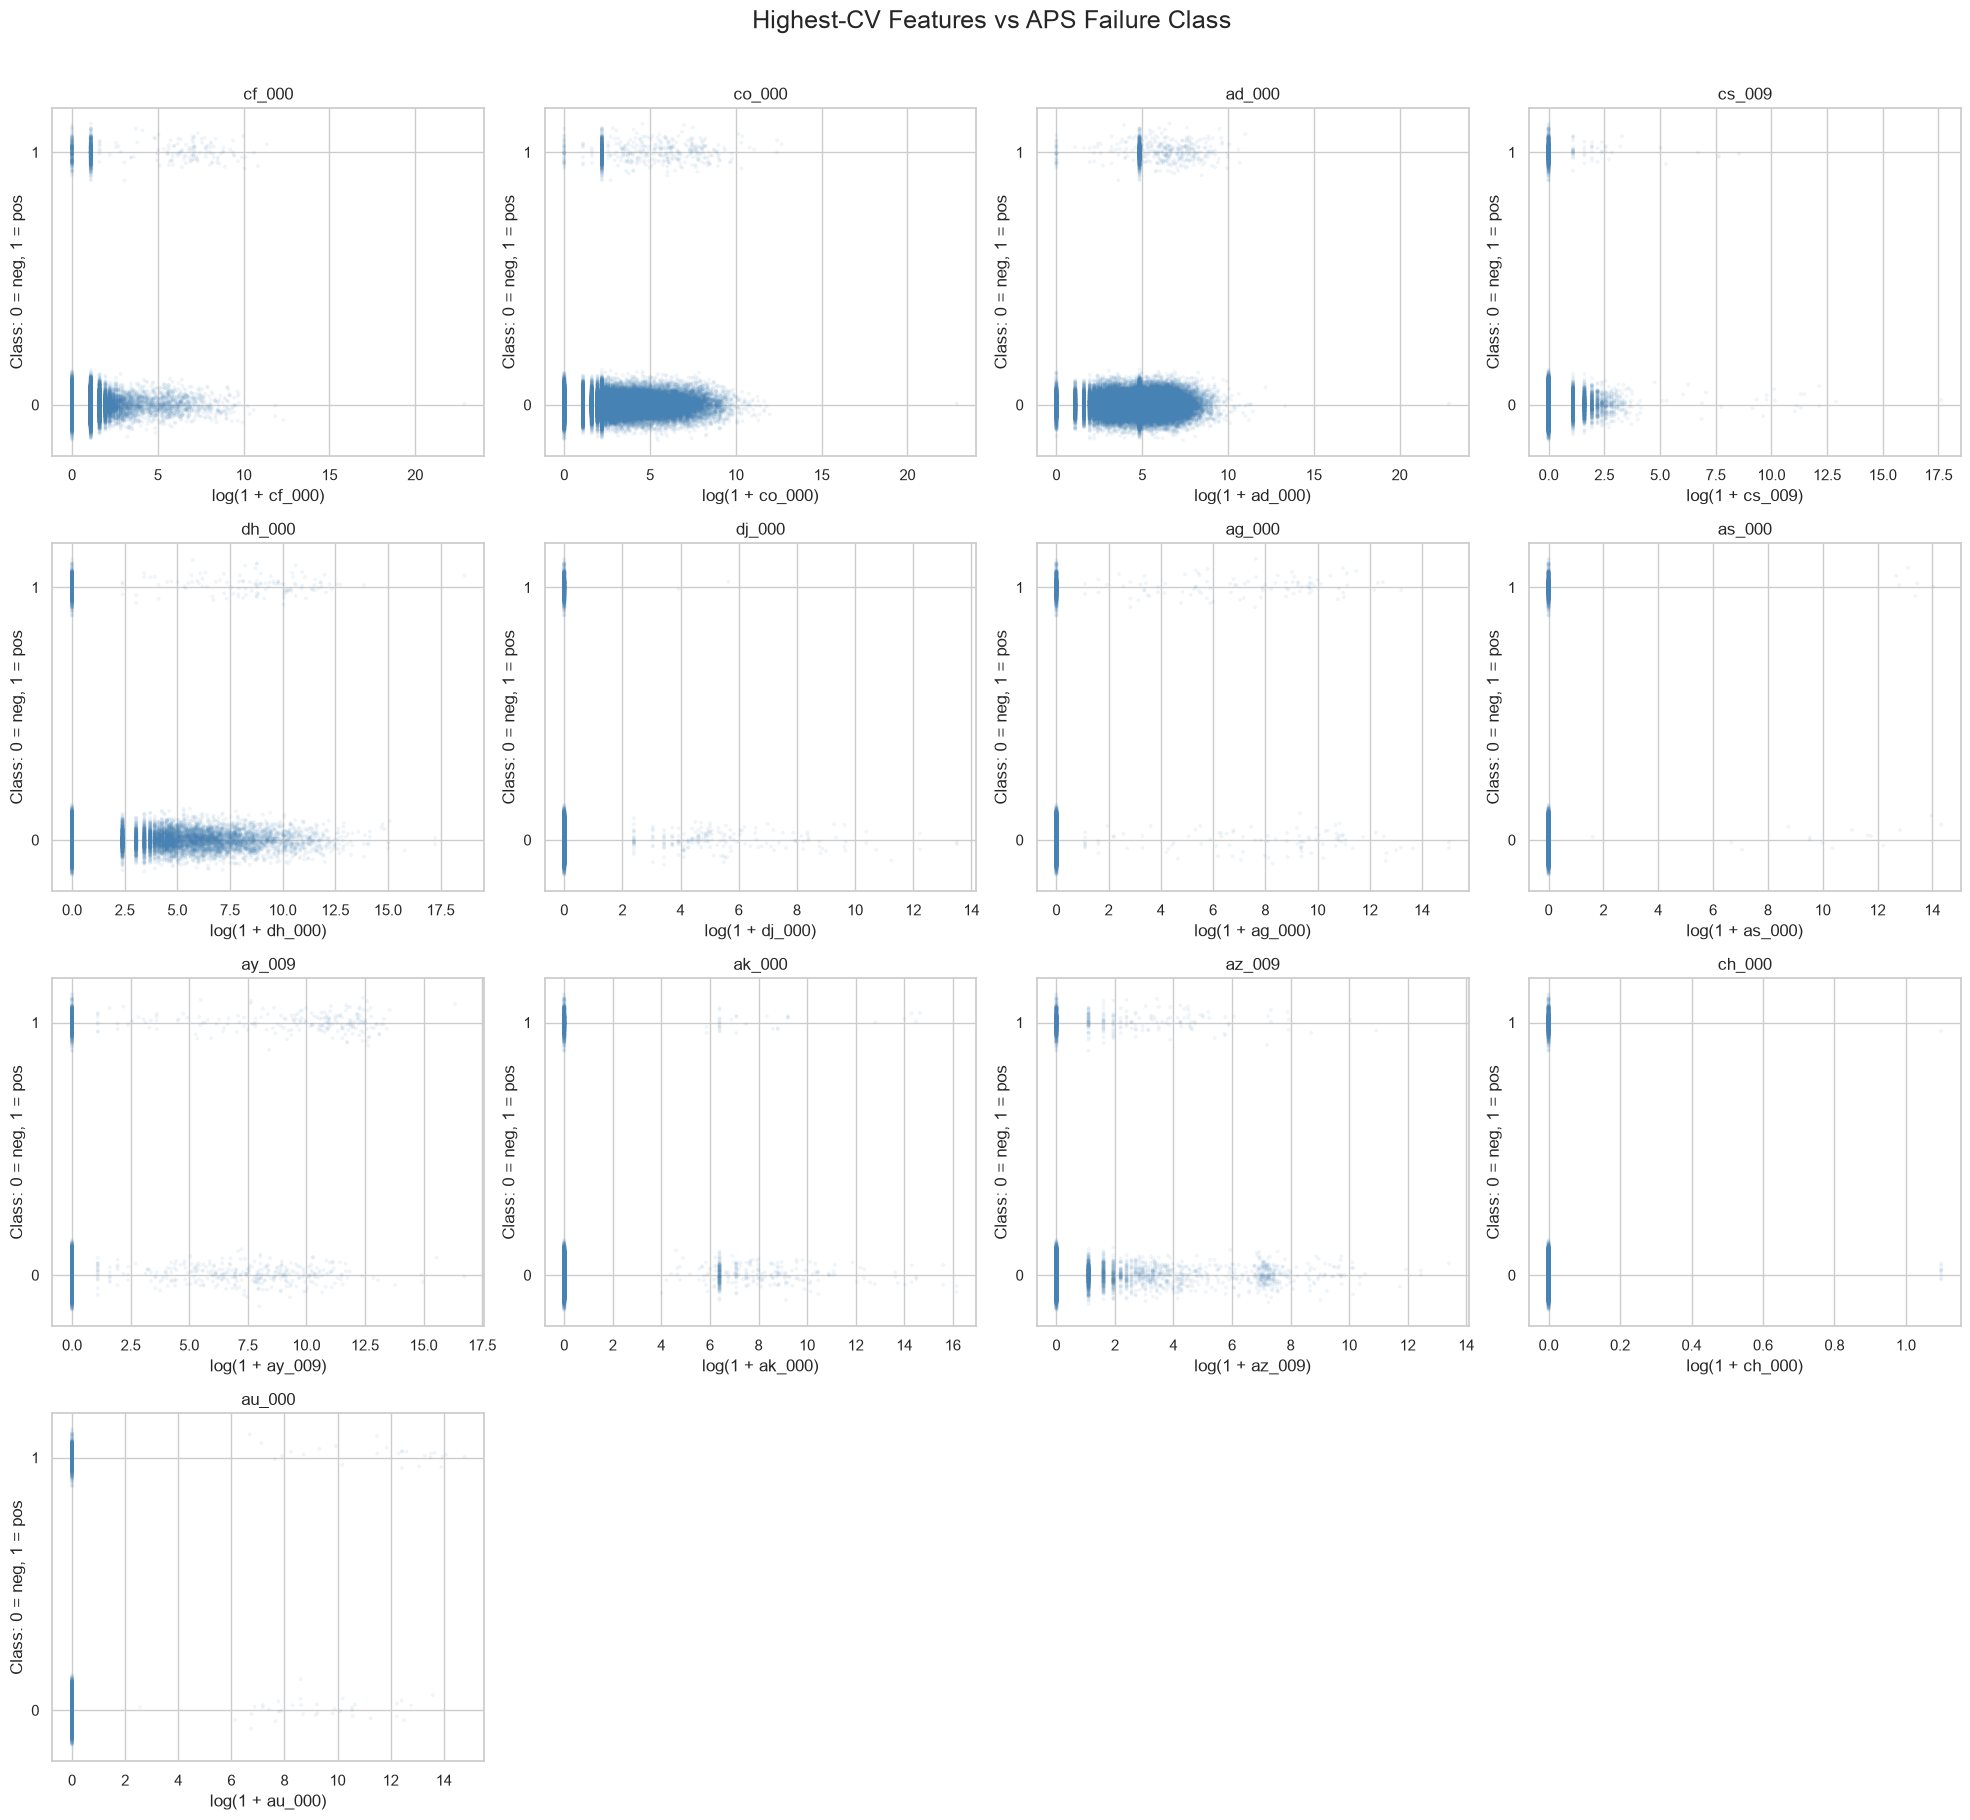

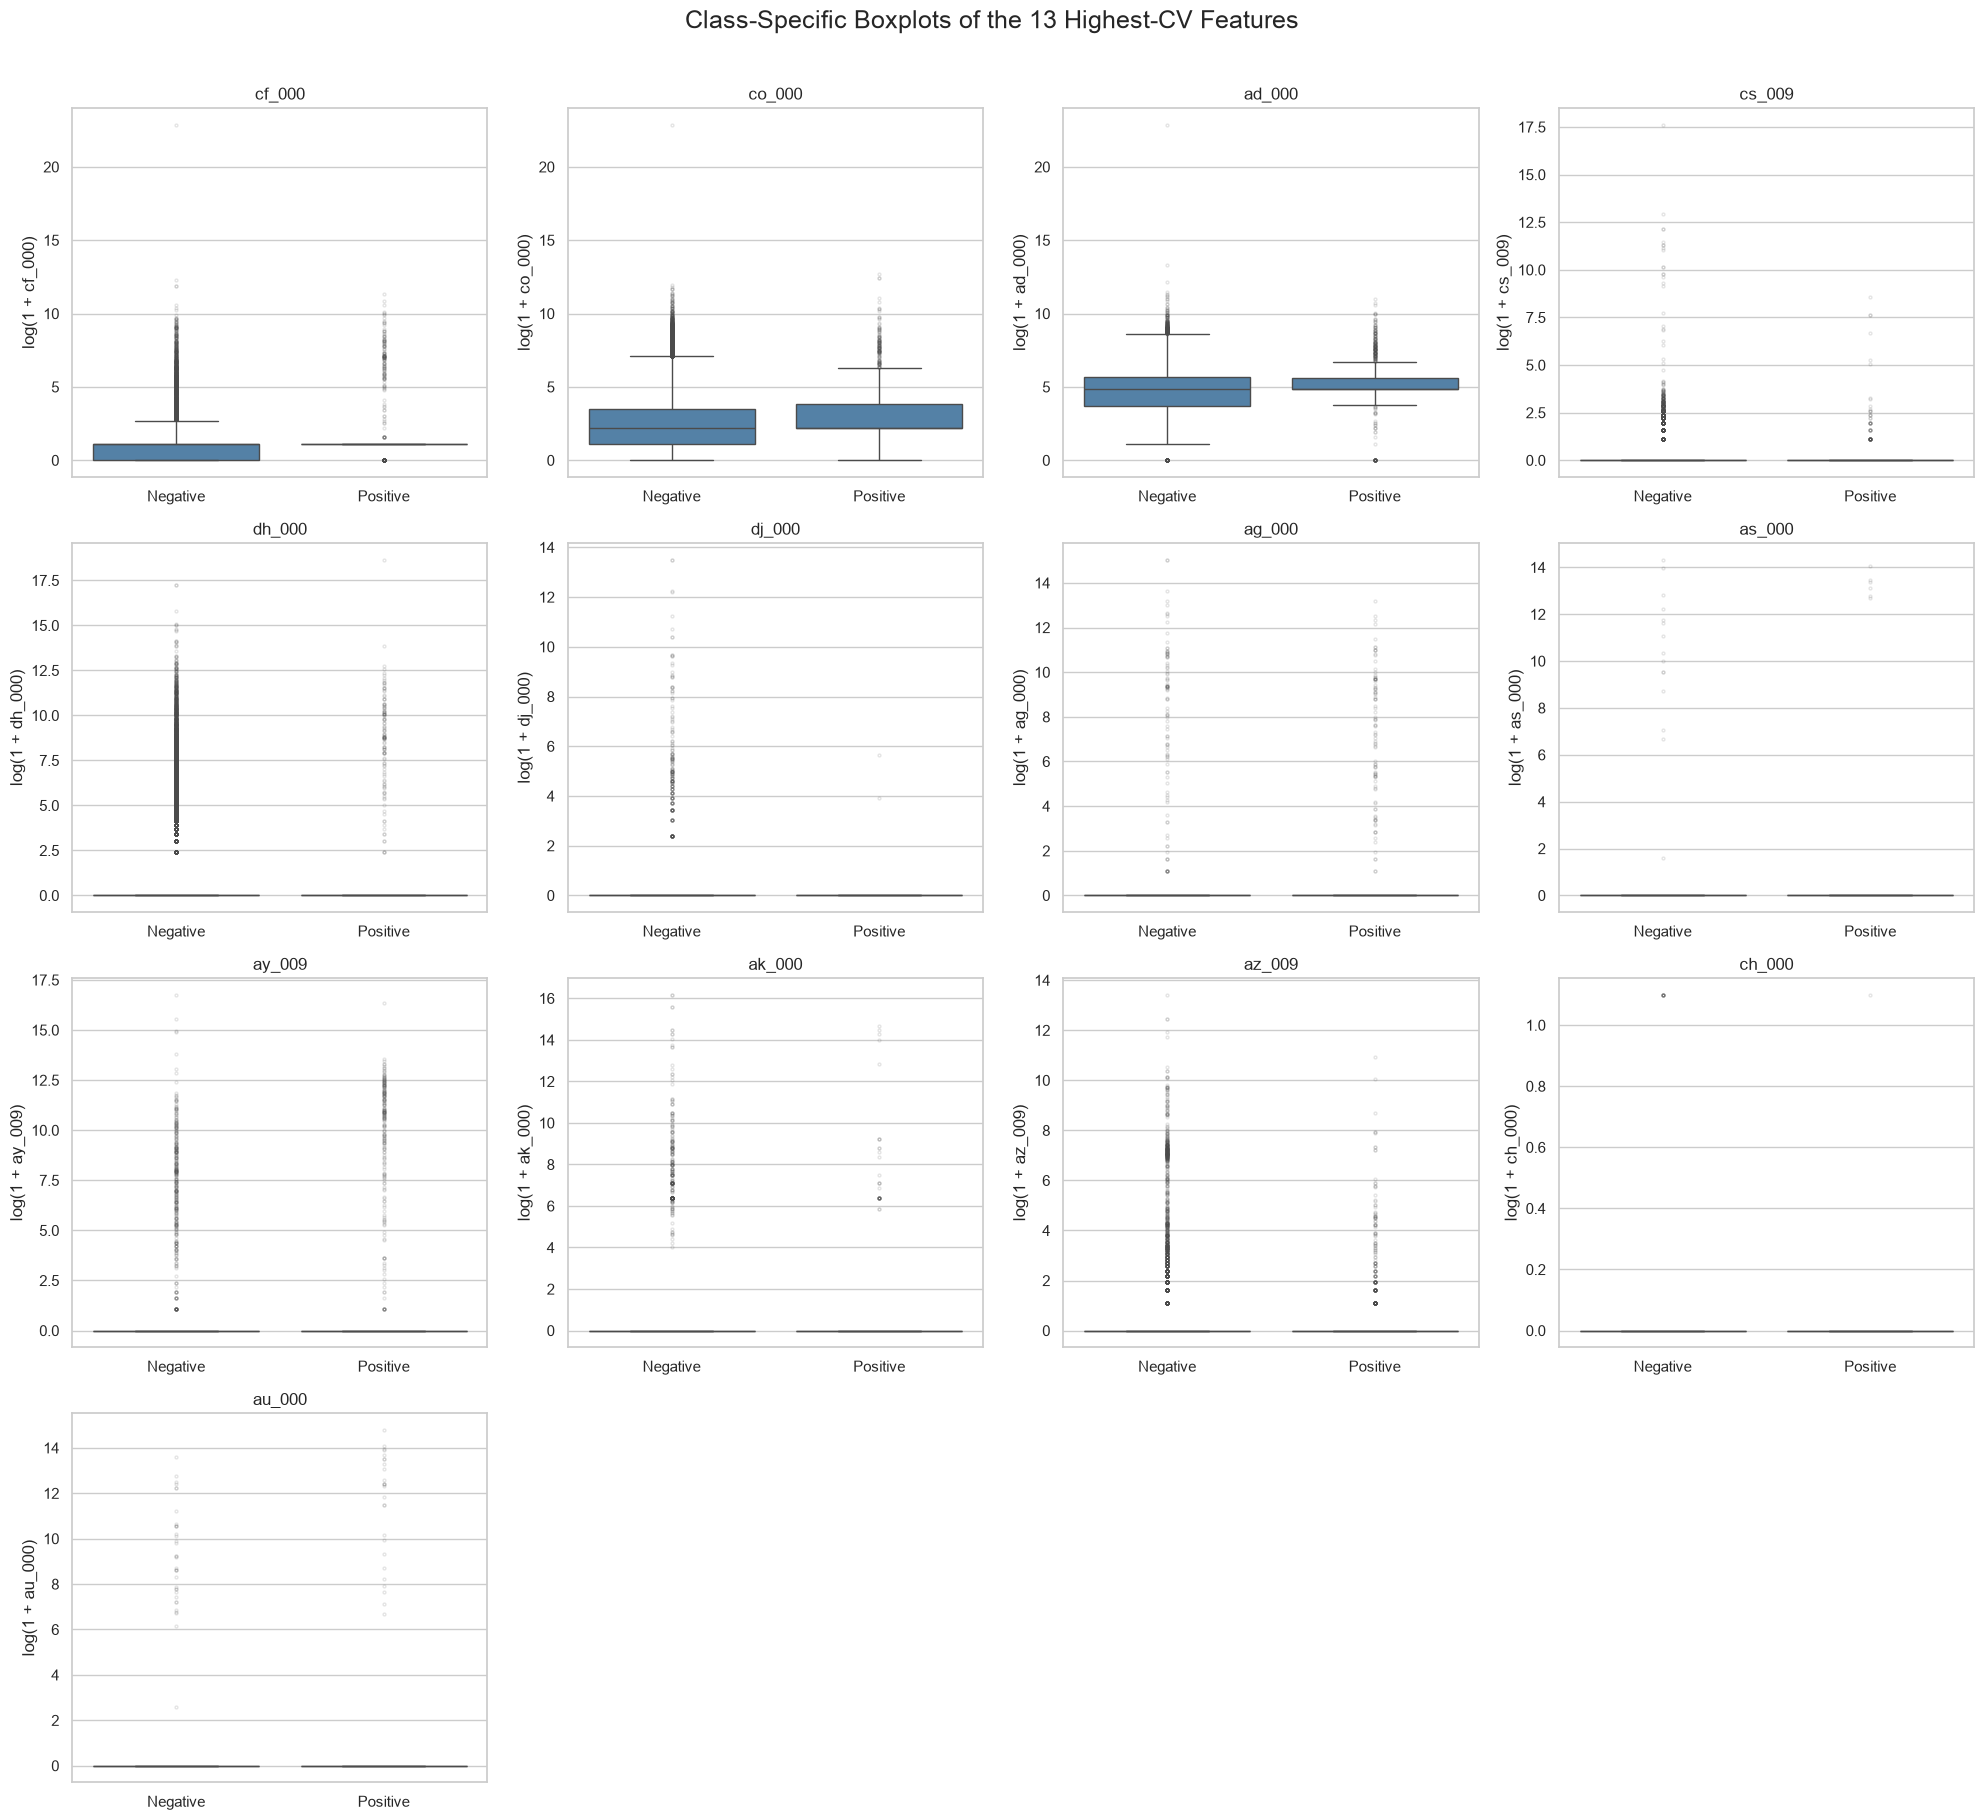

In [6]:
number_of_selected_features = int(np.floor(np.sqrt(170))) #floor(sqrt(170)) - 13 fts with the highest cv
highest_cv_features = cv_table.head(number_of_selected_features).index.tolist()

print("Number of selected features:", number_of_selected_features)
print("Features with the highest CV:")
for number, feature in enumerate(highest_cv_features, start=1):
    print(f"{number}. {feature}")

X_train_log = np.log1p(X_train[highest_cv_features]) #log1p for vis bc the features are skewed

#slight vertical jitter so can see overlapping class values
random_generator = np.random.default_rng(RANDOM_STATE)
jittered_class = (y_train.to_numpy() + random_generator.normal(0, 0.035, len(y_train)))

figure, axes = plt.subplots(4, 4, figsize=(20, 18)) #scatter plots against binary response
axes = axes.flatten()

for axis, feature in zip(axes, highest_cv_features):
    axis.scatter(X_train_log[feature], jittered_class, alpha=0.08, s=8, color="steelblue", edgecolor="none", rasterized=True)
    axis.set_title(feature)
    axis.set_xlabel(f"log(1 + {feature})")
    axis.set_ylabel("Class: 0 = neg, 1 = pos")
    axis.set_yticks([0, 1])

for unused_axis in axes[len(highest_cv_features):]:
    unused_axis.set_visible(False)
    
figure.suptitle("Highest-CV Features vs APS Failure Class", fontsize=18, y=1.01)
plt.tight_layout()
plt.show()

plot_data = X_train_log.copy() # class spec boxplots for same features
plot_data["class"] = y_train.map({0: "Negative", 1: "Positive"})

figure, axes = plt.subplots(4, 4, figsize=(20, 18))
axes = axes.flatten()

for axis, feature in zip(axes, highest_cv_features):
    sns.boxplot(data=plot_data, x="class", y=feature, order=["Negative", "Positive"], ax=axis, color="steelblue", showfliers=True, flierprops={"marker": "o", "markersize": 2, "alpha": 0.15})
    axis.set_title(feature)
    axis.set_xlabel("")
    axis.set_ylabel(f"log(1 + {feature})")

for unused_axis in axes[len(highest_cv_features):]:
    unused_axis.set_visible(False)

figure.suptitle("Class-Specific Boxplots of the 13 Highest-CV Features", fontsize=18, y=1.01)
plt.tight_layout()
plt.show()

#### Highest-CV Feature Interpretation
The 13 predictors with the highest coefficients of variation show substantial variability relative to their means. Several features, including `cs_009`, `dh_000`, `dj_000`, `ag_000`, `as_000`, `ay_009`, `ak_000`, `az_009`, and `au_000`, are highly zero-inflated. That means their large CV values are driven partly by small means and a relatively small number of large nonzero observations. The plots show that some features, such as `cf_000`, `co_000`, and `ad_000`, have different distributions between the positive and negative classes. But, there is also considerable overlap between the classes, and the number of positive observations is a lot smaller than the number of negative observations. Statistical significance can't be established from scatter plots or boxplots by themselves. These plots are useful for identifying possible patterns, skewness, outliers, and class differences, but formal statistical tests or predictive modeling would be needed to determine whether the features give us significant information after accounting for the other predictors.

#### (v) Is this data set imbalanced?

APS failure class distribution:


,Training Count,Training Percentage,Testing Count,Testing Percentage
Negative,59000,98.3333,15625,97.6562
Positive,1000,1.6667,375,2.3438


Training negative-to-positive ratio: 59.00:1
Testing negative-to-positive ratio: 41.67:1


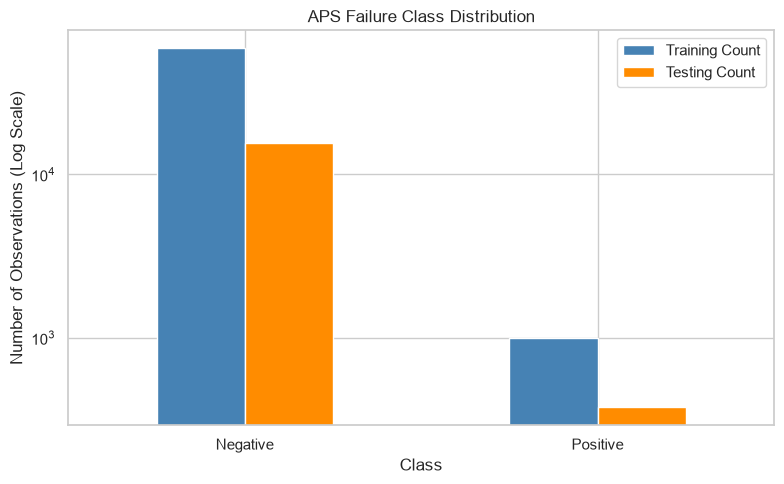

In [8]:
training_class_counts = y_train.value_counts().sort_index() #count pos and neg observations
testing_class_counts = y_test.value_counts().sort_index()
class_balance_table = pd.DataFrame({"Training Count": training_class_counts, "Training Percentage": (training_class_counts / len(y_train) * 100), "Testing Count": testing_class_counts, "Testing Percentage": (testing_class_counts / len(y_test) * 100)})
class_balance_table.index = ["Negative", "Positive"]
print("APS failure class distribution:")
display(class_balance_table.round(4))

training_imbalance_ratio = (training_class_counts[0] / training_class_counts[1])
testing_imbalance_ratio = (testing_class_counts[0] / testing_class_counts[1])
print("Training negative-to-positive ratio:", f"{training_imbalance_ratio:.2f}:1")
print("Testing negative-to-positive ratio:", f"{testing_imbalance_ratio:.2f}:1")

# Plot class counts on a logarithmic scale
class_balance_table[["Training Count", "Testing Count"]].plot(kind="bar", figsize=(8, 5), color=["steelblue", "darkorange"])
plt.yscale("log")
plt.ylabel("Number of Observations (Log Scale)")
plt.xlabel("Class")
plt.title("APS Failure Class Distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The dataset is severely imbalanced because the negative class greatly outnumbers the positive class

### (c) Train a random forest

### (d) Research class imbalance in random forest

### (e) XGBoost and Model Trees

### (f) Use SMOTE to pre-process your data

## 2. ISLR 6.6.3

## 3. ISLR 6.6.5

## 4. ISLR 8.4.5

## 5. ISLR 9.7.3